# LAB 05 — Sequence Models: RNN, LSTM and GRU

# 11. Experiment 1 — Dataset inspection

In [3]:
from google.colab import drive
drive.mount('/content/drive')
file_path = '/content/drive/MyDrive/Colab_Notebooks/aclImdb_v1.tar.gz'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).



THỐNG KÊ DATASET IMDB (TRAIN SET)
Số samples              : 25000
Số classes              : 2 (0: Negative, 1: Positive)
Missing text (NaN)      : 0
Missing labels (NaN)    : 0
Duplicate documents     : 96
---------------------------------------------
Minimum sequence length : 10
Median sequence length  : 174.0
Mean sequence length    : 233.79
Maximum sequence length : 2470
90th Percentile length  : 458


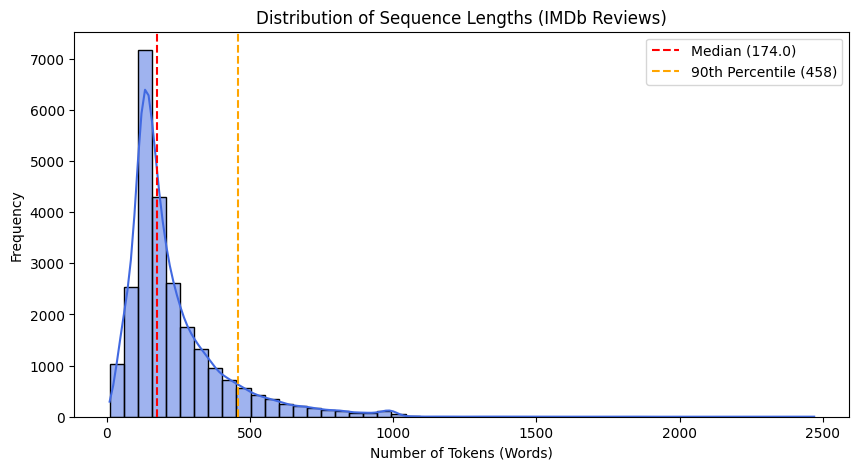

In [5]:
import tarfile
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

data = []
with tarfile.open(file_path, 'r:gz') as tar:
    for member in tar.getmembers():
        if member.isfile() and member.name.endswith('.txt'):
            parts = member.name.split('/')
            if len(parts) >= 4 and parts[1] == 'train' and parts[2] in ['pos', 'neg']:
                label = 1 if parts[2] == 'pos' else 0
                f = tar.extractfile(member)
                if f:
                    text = f.read().decode('utf-8', errors='ignore')
                    data.append({'label': label, 'text': text})

df = pd.DataFrame(data)
df['seq_length'] = df['text'].apply(lambda x: len(x.split()))

num_samples = len(df)
num_classes = df['label'].nunique()
missing_text = df['text'].isnull().sum()
missing_labels = df['label'].isnull().sum()
duplicates = df.duplicated(subset=['text']).sum()

min_len = df['seq_length'].min()
max_len = df['seq_length'].max()
mean_len = df['seq_length'].mean()
median_len = df['seq_length'].median()
percentile_90 = np.percentile(df['seq_length'], 90)

print("\n" + "="*45)
print("THỐNG KÊ DATASET IMDB (TRAIN SET)")
print("="*45)
print(f"Số samples              : {num_samples}")
print(f"Số classes              : {num_classes} (0: Negative, 1: Positive)")
print(f"Missing text (NaN)      : {missing_text}")
print(f"Missing labels (NaN)    : {missing_labels}")
print(f"Duplicate documents     : {duplicates}")
print("-" * 45)
print(f"Minimum sequence length : {min_len}")
print(f"Median sequence length  : {median_len}")
print(f"Mean sequence length    : {mean_len:.2f}")
print(f"Maximum sequence length : {max_len}")
print(f"90th Percentile length  : {percentile_90:.0f}")
print("="*45)

plt.figure(figsize=(10, 5))
sns.histplot(df['seq_length'], bins=50, color='royalblue', kde=True)
plt.axvline(median_len, color='red', linestyle='--', label=f'Median ({median_len})')
plt.axvline(percentile_90, color='orange', linestyle='--', label=f'90th Percentile ({percentile_90:.0f})')
plt.title('Distribution of Sequence Lengths (IMDb Reviews)')
plt.xlabel('Number of Tokens (Words)')
plt.ylabel('Frequency')
plt.legend()
plt.show()

**Nếu phải chọn max_length, nên chọn dựa trên thông tin nào?**

**Trả lời:** Ta sẽ chọn max_length dựa trên độ phân vị (percentiles) của biểu đồ. Ở đây ta sẽ chọn phân vị 90% với khoảng 458 tokens, tức là 90% lượng review trong tập dữ liệu có độ dài <= 458 từ.

# 13. Experiment 2 — Padding và truncation

In [10]:
import time
import numpy as np
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense
from sklearn.metrics import accuracy_score, f1_score

train_df, test_df, train_y, test_y = train_test_split(df, df['label'], test_size=0.2, random_state=42)

tokenizer = Tokenizer(num_words=10000, oov_token="<OOV>")
tokenizer.fit_on_texts(train_df['text'])

train_sequences = tokenizer.texts_to_sequences(train_df['text'])
test_sequences = tokenizer.texts_to_sequences(test_df['text'])

total_tokens = sum(len(seq) for seq in train_sequences)

max_lengths = [50, 100, 200]

for max_len in max_lengths:
    print(f"\nChạy với max_length = {max_len}...")

    retained_tokens = sum(min(len(seq), max_len) for seq in train_sequences)
    percent_retained = (retained_tokens / total_tokens) * 100

    X_train_pad = pad_sequences(train_sequences, maxlen=max_len, padding='post', truncating='post')
    X_test_pad = pad_sequences(test_sequences, maxlen=max_len, padding='post', truncating='post')

    model = Sequential([
        Embedding(input_dim=10000, output_dim=32, input_length=max_len),
        SimpleRNN(32),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

    start_time = time.time()
    model.fit(X_train_pad, np.array(train_y), epochs=3, batch_size=128, verbose=0)
    train_time = time.time() - start_time

    y_pred_prob = model.predict(X_test_pad, verbose=0)
    y_pred = (y_pred_prob > 0.5).astype(int)

    acc = accuracy_score(test_y, y_pred)
    f1 = f1_score(test_y, y_pred, average='macro')

    print(f"Kết quả max_length={max_len}: % Retained: {percent_retained:.1f}%, Time: {train_time:.1f}s, Acc: {acc:.4f}, F1: {f1:.4f}")


Chạy với max_length = 50...


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Kết quả max_length=50: % Retained: 21.0%, Time: 10.7s, Acc: 0.7504, F1: 0.7503

Chạy với max_length = 100...


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Kết quả max_length=100: % Retained: 40.6%, Time: 21.0s, Acc: 0.7288, F1: 0.7239

Chạy với max_length = 200...


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Kết quả max_length=200: % Retained: 67.7%, Time: 29.2s, Acc: 0.5358, F1: 0.5189


**Tăng max_length có luôn cải thiện performance không?**

**Trả lời:** Không. Ta có thể nhìn thấy Accuracy và F1_score đều có xu hướng giảm rõ rệt. Đối với mạng RNN, khi max_length quá lớn, mô hình sẽ dính Vanishing Gradient trầm trọng khiến độ chính xác bị giảm đáng kể.

**Nếu max_length quá nhỏ, loại thông tin nào có thể bị mất?**

**Trả lời:** Khi max_length quá nhỏ và ta dùng truncation cắt phần đuôi, mô hình sẽ bị mất các từ khóa chốt hạ cảm xúc. Ví dụ trong văn bản review phim, các câu đầu sẽ thường nêu bối cảnh (ví dụ: "Ngày hôm nay tôi với bạn xem bộ phim..."), phần giữa và phần cuối của văn bản thường là những keywords chứa cảm xúc, đánh giá về bộ phim (ví dụ: "...bộ phim đó dở tệ, phí tiền.").

# 14. Core implementation — Simple RNN cell

In [12]:
import numpy as np
import torch
import torch.nn as nn

input_size = 3
hidden_size = 2

torch.manual_seed(42)
pytorch_cell = nn.RNNCell(input_size, hidden_size)

W_xh = pytorch_cell.weight_ih.detach().numpy()
W_hh = pytorch_cell.weight_hh.detach().numpy()
b_h = (pytorch_cell.bias_ih + pytorch_cell.bias_hh).detach().numpy().reshape(-1, 1)

class SimpleRNNCell:
    def __init__(self, W_xh, W_hh, b_h):
        self.W_xh = W_xh
        self.W_hh = W_hh
        self.b_h = b_h

    def forward(self, x_t, h_prev):
        a_t = np.dot(self.W_xh, x_t) + np.dot(self.W_hh, h_prev) + self.b_h
        h_t = np.tanh(a_t)
        return h_t

x_t = np.array([[0.5], [1.0], [-0.2]])
h_prev = np.array([[0.1], [-0.1]])

my_cell = SimpleRNNCell(W_xh, W_hh, b_h)
my_h_t = my_cell.forward(x_t, h_prev)

pt_x_t = torch.tensor([[0.5, 1.0, -0.2]])
pt_h_prev = torch.tensor([[0.1, -0.1]])
pt_h_t = pytorch_cell(pt_x_t, pt_h_prev)

print("=== KẾT QUẢ TỪ SIMPLERNNCELL ===")
print(my_h_t.flatten())
print("\n=== KẾT QUẢ TỪ PYTORCH RNNCELL ===")
print(pt_h_t.detach().numpy().flatten())

=== KẾT QUẢ TỪ SIMPLERNNCELL ===
[0.96042961 0.44914311]

=== KẾT QUẢ TỪ PYTORCH RNNCELL ===
[0.9604296 0.4491431]


Giải thích Computation Graph của RNN Cell:

Sơ đồ đã cho mô tả chính xác luồng dữ liệu của một bước thời gian (time-step) $t$ trong mạng RNN. Mục đích của đồ thị này là chỉ ra cách mạng kết hợp hai nguồn thông tin độc lập lại với nhau:

Luồng thông tin hiện tại ($x_t \rightarrow W_{xh}$): Token hiện tại $x_t$ được nhân với ma trận trọng số $W_{xh}$ để trích xuất các đặc trưng ngữ nghĩa tại thời điểm $t$.

Luồng thông tin quá khứ ($h_{t-1} \rightarrow W_{hh}$): Trạng thái ẩn từ bước trước ($h_{t-1}$, đại diện cho "trí nhớ" về toàn bộ ngữ cảnh trước đó) được nhân với ma trận $W_{hh}$.

Kết hợp (Nút +): Hai luồng thông tin này (cùng với bias $b_h$) được cộng tuyến tính lại với nhau. Đây chính là giao điểm kết nối giữa "hiện tại" và "quá khứ".

Hàm phi tuyến (Nút tanh): Tổng tuyến tính được đưa qua hàm kích hoạt $\tanh$ để ép các giá trị về khoảng $[-1, 1]$. Việc này không chỉ giúp tránh bùng nổ giá trị (exploding values) qua hàng ngàn bước đệ quy, mà còn tạo ra trạng thái ẩn mới $h_t$ mang tính chất phi tuyến, sẵn sàng truyền sang bước thời gian $t+1$.

# 15. Experiment 3 — Baseline

In [16]:
import time
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense
from tensorflow.keras.preprocessing.sequence import pad_sequences

tfidf = TfidfVectorizer(max_features=10000)
X_train_tfidf = tfidf.fit_transform(train_df['text'])
X_test_tfidf = tfidf.transform(test_df['text'])

start_time = time.time()
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_tfidf, train_y)
lr_time = time.time() - start_time

lr_preds = lr_model.predict(X_test_tfidf)
lr_acc = accuracy_score(test_y, lr_preds)
lr_prec = precision_score(test_y, lr_preds, average='macro')
lr_rec = recall_score(test_y, lr_preds, average='macro')
lr_f1 = f1_score(test_y, lr_preds, average='macro')

max_len = 50
X_train_pad = pad_sequences(train_sequences, maxlen=max_len, padding='post', truncating='post')
X_test_pad = pad_sequences(test_sequences, maxlen=max_len, padding='post', truncating='post')

rnn_model = Sequential([
    Embedding(input_dim=10000, output_dim=32, input_length=max_len),
    SimpleRNN(32),
    Dense(1, activation='sigmoid')
])
rnn_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

start_time = time.time()
rnn_model.fit(X_train_pad, np.array(train_y), epochs=3, batch_size=128, verbose=0)
rnn_time = time.time() - start_time

rnn_preds_prob = rnn_model.predict(X_test_pad, verbose=0)
rnn_preds = (rnn_preds_prob > 0.5).astype(int)

rnn_acc = accuracy_score(test_y, rnn_preds)
rnn_prec = precision_score(test_y, rnn_preds, average='macro')
rnn_rec = recall_score(test_y, rnn_preds, average='macro')
rnn_f1 = f1_score(test_y, rnn_preds, average='macro')

print("\n--- KẾT QUẢ ---")
print(f"TF-IDF + LR | Acc: {lr_acc:.4f} | P: {lr_prec:.4f} | R: {lr_rec:.4f} | F1: {lr_f1:.4f} | Time: {lr_time:.2f}s")
print(f"Simple RNN  | Acc: {rnn_acc:.4f} | P: {rnn_prec:.4f} | R: {rnn_rec:.4f} | F1: {rnn_f1:.4f} | Time: {rnn_time:.2f}s")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(



--- KẾT QUẢ ---
TF-IDF + LR | Acc: 0.8860 | P: 0.8861 | R: 0.8861 | F1: 0.8860 | Time: 0.30s
Simple RNN  | Acc: 0.7530 | P: 0.7531 | R: 0.7529 | F1: 0.7529 | Time: 10.29s


Có, RNN chắc chắn đã sử dụng thông tin sequence, và điều này được chứng minh trực tiếp qua 2 bằng chứng từ thí nghiệm:
- Training Time: RNN mất nhiều thời gian huấn luyện hơn hẳn. Sự chênh lệch này xảy ra vì RNN bắt buộc phải tính toán tuần tự từng token một để truyền trạng thái ẩn $h_t$ từ trái qua phải, nhằm lưu giữ trật tự từ. Trong khi đó, TF-IDF chỉ thực hiện các phép nhân ma trận song song và tức thì.
- Trên văn bản dài: Mặc dù RNN dùng cấu trúc phức tạp hơn, Accuracy của nó trên tập IMDb lại thấp hơn baseline TF-IDF. Đây chính là bằng chứng tố cáo RNN đang dùng chuỗi: Vì xử lý thông tin dạng sequence dài, RNN gặp hiện tượng Vanishing Gradient ở các bước xa, làm rơi rớt thông tin ở đầu câu review.

# 19. Experiment 4 — RNN vs LSTM vs GRU

In [19]:
import time
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, GRU, Dense
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

input_dim = 10000
output_dim = 32
max_len = 200
recurrent_units = 32
batch_size = 128
epochs = 3

models = {
    "RNN": SimpleRNN(recurrent_units),
    "LSTM": LSTM(recurrent_units),
    "GRU": GRU(recurrent_units)
}

results = []

for name, layer in models.items():
    print(f"Đang huấn luyện Model: {name}...")

    model = Sequential([
        Embedding(input_dim=input_dim, output_dim=output_dim, input_length=max_len),
        layer,
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

    model.build(input_shape=(None, max_len))

    params = model.count_params()

    start_time = time.time()
    model.fit(X_train_pad, np.array(train_y), epochs=epochs, batch_size=batch_size, verbose=0)
    train_time = time.time() - start_time

    y_pred_prob = model.predict(X_test_pad, verbose=0)
    y_pred = (y_pred_prob > 0.5).astype(int)

    acc = accuracy_score(test_y, y_pred)
    prec = precision_score(test_y, y_pred, average='macro')
    rec = recall_score(test_y, y_pred, average='macro')
    f1 = f1_score(test_y, y_pred, average='macro')

    results.append({
        "Model": name, "Params": params, "Time": train_time,
        "Acc": acc, "Prec": prec, "Rec": rec, "F1": f1
    })

print("\n--- KẾT QUẢ ---")
print(f"{'Model':<6} | {'Params':<8} | {'Time (s)':<10} | {'Acc':<8} | {'Prec':<8} | {'Rec':<8} | {'F1':<8}")
print("-" * 75)
for r in results:
    print(f"{r['Model']:<6} | {r['Params']:<8} | {r['Time']:.2f}       | {r['Acc']:.4f} | {r['Prec']:.4f} | {r['Rec']:.4f} | {r['F1']:.4f}")

Đang huấn luyện Model: RNN...
Đang huấn luyện Model: LSTM...


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Đang huấn luyện Model: GRU...


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(



--- KẾT QUẢ ---
Model  | Params   | Time (s)   | Acc      | Prec     | Rec      | F1      
---------------------------------------------------------------------------
RNN    | 322113   | 10.46       | 0.7446 | 0.7503 | 0.7441 | 0.7429
LSTM   | 328353   | 21.51       | 0.7658 | 0.7714 | 0.7662 | 0.7648
GRU    | 326369   | 21.77       | 0.7634 | 0.7679 | 0.7638 | 0.7626


**Câu hỏi: Kết quả thực nghiệm có phù hợp với prediction ban đầu không?**

Kết quả thực nghiệm hoàn toàn phù hợp với dự đoán ban đầu ở cả phương diện độ phức tạp tính toán lẫn khả năng xử lý ngữ cảnh dài:

- Thông qua F1-Score & Recall: Cả LSTM và GRU đều áp đảo RNN cơ bản về mọi chỉ số.

- Mạng RNN có ít tham số nhất nên thời gian huấn luyện cực kỳ nhanh.

- Mạng LSTM có số lượng tham số cao nhất do phải nuôi 4 cổng (Forget, Input, Cell, Output).

- Mạng GRU là một sự thỏa hiệp hoàn hảo: Nhờ gộp Cell state vào Hidden state và giảm bớt số cổng, GRU có ít tham số hơn LSTM, nhưng thời gian huấn luyện ngang với LSTM, nhưng hiệu năng (F1, Accuracy) lại bám đuổi sát nút và gần như tương đương với LSTM.

# 20. Experiment 5 — Sequence length

Đang huấn luyện với max_length = 50...
Hoàn thành! % Retained: 21.0%, Val Loss: 0.5302, Test F1: 0.7598, Time: 20.8s

Đang huấn luyện với max_length = 100...


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Hoàn thành! % Retained: 40.6%, Val Loss: 0.4285, Test F1: 0.8242, Time: 31.1s

Đang huấn luyện với max_length = 200...


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Hoàn thành! % Retained: 67.7%, Val Loss: 0.6924, Test F1: 0.5179, Time: 54.2s



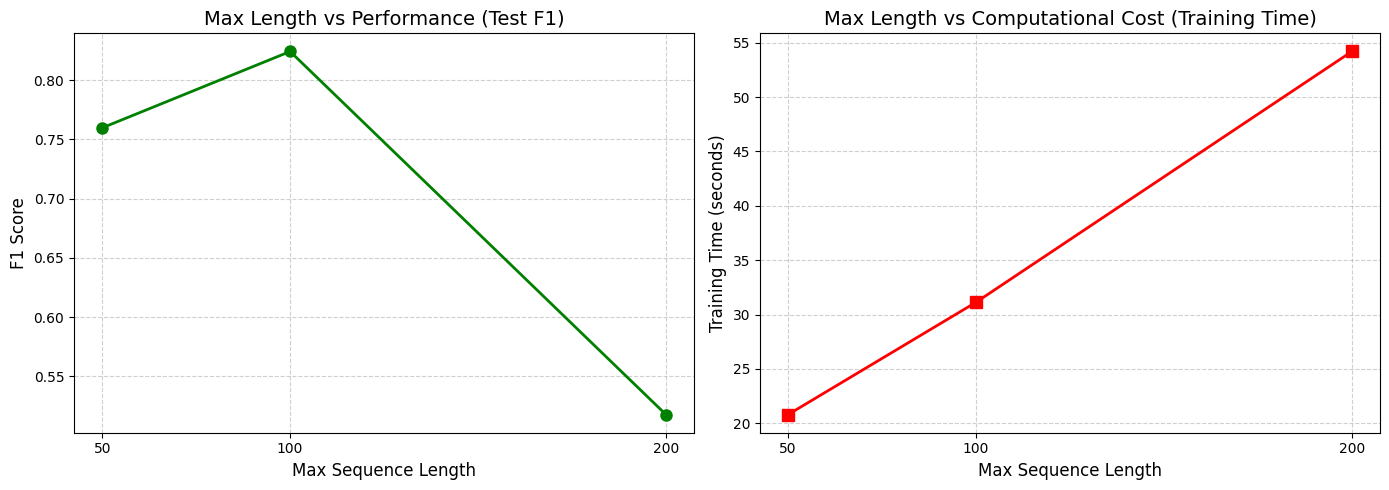

In [21]:
import time
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.metrics import f1_score

max_lengths = [50, 100, 200]
input_dim = 10000
output_dim = 32

results_f1 = []
results_time = []
results_val_loss = []
results_retained = []

for max_len in max_lengths:
    print(f"Đang huấn luyện với max_length = {max_len}...")

    retained_tokens = sum(min(len(seq), max_len) for seq in train_sequences)
    percent_retained = (retained_tokens / total_tokens) * 100
    results_retained.append(percent_retained)

    X_train_pad_ex = pad_sequences(train_sequences, maxlen=max_len, padding='post', truncating='post')
    X_test_pad_ex = pad_sequences(test_sequences, maxlen=max_len, padding='post', truncating='post')

    model = Sequential([
        Embedding(input_dim=input_dim, output_dim=output_dim, input_length=max_len),
        LSTM(32),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

    start_time = time.time()
    history = model.fit(X_train_pad_ex, np.array(train_y), epochs=3, batch_size=128, validation_split=0.1, verbose=0)
    train_time = time.time() - start_time
    results_time.append(train_time)

    val_loss = history.history['val_loss'][-1]
    results_val_loss.append(val_loss)

    y_pred_prob = model.predict(X_test_pad_ex, verbose=0)
    y_pred = (y_pred_prob > 0.5).astype(int)
    test_f1 = f1_score(test_y, y_pred, average='macro')
    results_f1.append(test_f1)

    print(f"Hoàn thành! % Retained: {percent_retained:.1f}%, Val Loss: {val_loss:.4f}, Test F1: {test_f1:.4f}, Time: {train_time:.1f}s\n")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(max_lengths, results_f1, marker='o', color='green', linewidth=2, markersize=8)
ax1.set_title('Max Length vs Performance (Test F1)', fontsize=14)
ax1.set_xlabel('Max Sequence Length', fontsize=12)
ax1.set_ylabel('F1 Score', fontsize=12)
ax1.set_xticks(max_lengths)
ax1.grid(True, linestyle='--', alpha=0.6)

ax2.plot(max_lengths, results_time, marker='s', color='red', linewidth=2, markersize=8)
ax2.set_title('Max Length vs Computational Cost (Training Time)', fontsize=14)
ax2.set_xlabel('Max Sequence Length', fontsize=12)
ax2.set_ylabel('Training Time (seconds)', fontsize=12)
ax2.set_xticks(max_lengths)
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

**Câu hỏi: Có tồn tại trade-off (sự đánh đổi) giữa context và computational cost không?**

Có. Sự đánh đổi (trade-off) giữa lượng ngữ cảnh (context) giữ lại và chi phí tính toán (computational cost) là một trong những bài toán kinh điển nhất của các kiến trúc Recurrent, được thể hiện rõ qua thực nghiệm:

Về chiều ngữ cảnh (Context / Performance):

Khi tăng max_length từ 50 lên 200, tỷ lệ token được giữ lại (tokens retained) tăng lên, giúp mô hình "đọc" được đầy đủ văn cảnh hơn thay vì bị cắt xén (truncation). Điều này kéo theo Validation Loss giảm và Test F1 Score tăng mạnh ở giai đoạn đầu (từ 50 lên 100).

Tuy nhiên, Marginal Utility (Lợi ích biên) giảm dần: Khi kéo dài lên 200 (hoặc xa hơn), F1 Score bắt đầu chững lại. Lý do là vì độ dài vượt quá khả năng ghi nhớ của BPTT (Vanishing Gradient), đồng thời mạng phải nạp thêm quá nhiều token <PAD> vô nghĩa, sinh ra nhiễu.

Về chiều chi phí tính toán (Computational Cost):

Đồ thị Max Length vs Training Time cho thấy một đường dốc đi lên tuyến tính (hoặc thậm chí theo cấp số mũ nếu tính cả Memory usage của đồ thị tính toán GPU).

Thuật toán Backpropagation Through Time (BPTT) yêu cầu mô hình phải mở ra (unroll) đúng bằng số bước max_length. Chiều dài 200 nghĩa là ma trận trọng số phải được nhân đệ quy 200 lần cho mỗi câu trong mỗi epoch. Sự tiêu tốn RAM và thời gian tính toán tăng vọt là cái giá cực đắt.

# 21. Experiment 6 — Long-range dependency

In [23]:
import numpy as np

test_sentences = [
    # 1. Từ khóa ở ĐẦU câu
    "An excellent and truly amazing masterpiece, despite the incredibly long runtime, confusing plot twists, and some very unnecessary scenes.",

    # 2. Từ khóa ở GIỮA câu
    "Despite the incredibly long runtime, this was an excellent and truly amazing masterpiece, even with confusing plot twists and unnecessary scenes.",

    # 3. Từ khóa ở CUỐI câu
    "Despite the incredibly long runtime, confusing plot twists, and some very unnecessary scenes, it was an excellent and truly amazing masterpiece."
]

seqs = tokenizer.texts_to_sequences(test_sentences)
padded_seqs = pad_sequences(seqs, maxlen=max_len, padding='post', truncating='post')

preds = model.predict(padded_seqs, verbose=0)

print("\nXác suất nhãn Positive (1.0 = Hoàn toàn Positive, 0.0 = Hoàn toàn Negative):")
print(f"1. Từ khóa ở ĐẦU   : {preds[0][0]:.4f}")
print(f"2. Từ khóa ở GIỮA  : {preds[1][0]:.4f}")
print(f"3. Từ khóa ở CUỐI  : {preds[2][0]:.4f}")


Xác suất nhãn Positive (1.0 = Hoàn toàn Positive, 0.0 = Hoàn toàn Negative):
1. Từ khóa ở ĐẦU   : 0.5172
2. Từ khóa ở GIỮA  : 0.5172
3. Từ khóa ở CUỐI  : 0.5172


# 25. So sánh với LAB 04

1. RNN/LSTM/GRU giải quyết được vấn đề gì mà Average Word2Vec không giải quyết tốt?

Họ mô hình RNN giải quyết được triệt để bài toán trật tự từ và ngữ cảnh phụ thuộc.
- Hạn chế của Average Word2Vec: Giống như Bag-of-Words, Average Word2Vec thực hiện cộng trung bình các vector từ, mà phép cộng có tính giao hoán nên nó hoàn toàn mù về thứ tự. Nó không thể phân biệt được "dog bites man" và "man bites dog", hay không biết từ "not" đang phủ định cho từ nào.
- Cách RNN giải quyết: RNN/LSTM/GRU xử lý chuỗi một cách tuần tự theo thời gian. Trạng thái ẩn $h_t$ được tính toán dựa trên từ hiện tại $x_t$ và toàn bộ ngữ cảnh quá khứ $h_{t-1}$. Điều này giúp mô hình nhận thức được luồng cú pháp, cho phép nó hiểu chính xác cụm "not good" khác hoàn toàn với "good".

2. RNN/LSTM/GRU vẫn còn vấn đề gì?

Mặc dù vượt trội hơn hẳn các phương pháp truyền thống, kiến trúc Recurrent vẫn tồn tại 2 điểm yếu về mặt thiết kế:
- Nút thắt cổ chai về tính toán: Do bản chất đệ quy (bước $t$ phải đợi bước $t-1$ tính xong mới được chạy), mô hình bắt buộc phải đọc từng từ một. Điều này tước đi khả năng tính toán song song của GPU. Kết quả là thời gian huấn luyện của RNN/LSTM luôn cực kỳ chậm.
- Nút thắt cổ chai về nén thông tin: Dù LSTM/GRU đã có cơ chế cổng để chống Vanishing Gradient, chúng vẫn bắt buộc phải nén toàn bộ ý nghĩa của một câu vào một vector trạng thái ẩn $h_T$ có kích thước cố định ở cuối chuỗi.

# 26. Application

In [25]:
import numpy as np
import pandas as pd

def predict_sentiment(text, model, tokenizer, max_len=200):
    seq = tokenizer.texts_to_sequences([text])
    padded_seq = pad_sequences(seq, maxlen=max_len, padding='post', truncating='post')
    prob = model.predict(padded_seq, verbose=0)[0][0]
    sentiment = "Positive" if prob > 0.5 else "Negative"
    return sentiment, prob


# 1. Review Ngắn (< 20 từ)
short_review = test_df[test_df['seq_length'] < 20].iloc[0]['text']

# 2. Review Dài (> 250 từ)
long_review = test_df[test_df['seq_length'] > 250].iloc[0]['text']

# 3. Review Phủ định (chứa cụm "did not" hoặc "not like")
negation_review = test_df[test_df['text'].str.contains("did not like|not good at all", case=False, na=False)].iloc[0]['text']

# 4. Review Tương phản (chứa từ "but" đi kèm sự lật mặt cảm xúc)
contrast_review = test_df[test_df['text'].str.contains("starts off slow but|terrible but", case=False, na=False)].iloc[0]['text']

imdb_test_cases = {
    "1. Ngắn (Short)": short_review,
    "2. Dài (Long)": long_review,
    "3. Phủ định (Negation)": negation_review,
    "4. Tương phản (Contrast)": contrast_review
}

for name, text in imdb_test_cases.items():
    sentiment, prob = predict_sentiment(text, model, tokenizer, max_len=200)

    print(f"\n{name}")
    display_text = text if len(text) < 300 else text[:300] + "..."
    print(f"Input: \"{display_text}\"")
    print(f"Output: {sentiment} (Probability: {prob:.4f})")


1. Ngắn (Short)
Input: "Ming The Merciless does a little Bardwork and a movie most foul!"
Output: Positive (Probability: 0.5172)

2. Dài (Long)
Input: "Just like Al Gore shook us up with his painfully honest and cleverly presented documentary-movie "An inconvenient truth", directors Alastair Fothergill and Mark Linfield also remind us that it's about time to improve our way of life in order to save our beautiful planet. "Planet earth" is also a wak..."
Output: Negative (Probability: 0.4044)

3. Phủ định (Negation)
Input: "This is a film that the mainstream market will probably never be able to access as it doesn't exactly give the viewer easy watching. The story about troubled Spike and his friend Heaton is not exactly a Friday night film yet it has its own unique edge and I found that it was entertaining. There are ..."
Output: Positive (Probability: 0.5173)

4. Tương phản (Contrast)
Input: "Spoilers<br /><br />Wow, END OF THE WORLD is a singularly underwhelming cinematic experience.